# Mô Phỏng 3D Trực Quan Tác Tử Săn Mồi GridHunt (GridHunt 3D Simulation)

Chào mừng bạn đến với **Mô phỏng 3D GridHunt**! Notebook này nâng cấp bài toán săn quái vật truyền thống từ bàn cờ phẳng 2D lên **không gian trực quan hóa 3 chiều**, kết hợp công nghệ đồ họa WebGL hiện đại để mang lại trải nghiệm quan sát sống động và trực quan nhất:

---

### Các tính năng nổi bật trong Notebook:
1. **Mô phỏng 3D Động Tương Tác (Plotly WebGL)**:
   - Toàn bộ bàn cờ, nhân vật **Thợ săn (Hunter - Xanh Cyan)** và **Quái vật (Monster - Đỏ Neon)** được mô phỏng trong không gian 3 chiều.
   - Hiệu ứng **Sóng âm Radar (Sonar Wave)** lan tỏa khi Thợ săn chọn hành động `'listen'`.
   - Hiệu ứng **Bắt giữ (Starburst Flash)** rực rỡ khi Thợ săn tóm gọn Quái vật.
   - Tích hợp thanh điều khiển **Play / Pause** và **Thanh trượt thời gian (Timeline Slider)** cho phép xoay 360 độ, phóng to, thu nhỏ và quan sát từng bước đi.
2. **Biểu đồ Quỹ đạo Không - Thời gian 3D (3D Spacetime Trajectory - Matplotlib)**:
   - Mô hình hóa quỹ đạo theo hệ trục 3 chiều $(X, Y, t)$, trong đó trục $Z$ là bước thời gian.
   - Thể hiện rõ nét quá trình khép góc và hội tụ của Thợ săn về phía Quái vật.
3. **Thử nghiệm So sánh Đa Kịch bản**:
   - So sánh trực quan giữa **Quái vật ngẫu nhiên** và **Quái vật thông minh biết né tránh chủ động (Evasive Monster)**.


In [1]:

import sys
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
import plotly.io as pio

# Thiết lập renderer Plotly để tương thích hoàn hảo trong VS Code và Jupyter Notebook
pio.renderers.default = "notebook_connected"

# Thiết lập thẩm mỹ cho Matplotlib
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

print("✓ Đã tải thành công các thư viện: NumPy, Matplotlib (mplot3d), Plotly 3D WebGL.")


✓ Đã tải thành công các thư viện: NumPy, Matplotlib (mplot3d), Plotly 3D WebGL.


In [2]:
def arena_environment_3d(hunter_agent_function, 
                         monster_agent_function, 
                         n = 15, max_steps = 40):
    """
    Môi trường GridHunt 3D thu thập toàn bộ lịch sử tọa độ và hành động của các tác tử.
    
    Tham số:
    hunter_agent_function: Hàm tác tử Thợ săn.
    monster_agent_function: Hàm tác tử Quái vật.
    n (int): Kích thước bàn cờ (n x n).
    max_steps (int): Số bước tối đa của ván đấu.
    
    Trả về:
    dict: Lịch sử đầy đủ gồm tọa độ, hành động, khoảng cách và sự kiện.
    """
    # Khởi tạo vị trí ngẫu nhiên không trùng nhau
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_pos, monster_pos):
        hunter_pos = np.random.randint(0, n-1, size=2)
        
    def move(action, position):
        pos = position.copy()
        if action == 'north':   pos[0] -= 1
        elif action == 'south': pos[0] += 1
        elif action == 'west':  pos[1] -= 1
        elif action == 'east':  pos[1] += 1
        return np.clip(pos, 0, n-1)

    history = {
        'n': n,
        'steps': [],
        'hunter_coords': [],
        'monster_coords': [],
        'hunter_actions': [],
        'monster_actions': [],
        'distances': [],
        'listened_steps': [],
        'caught_step': None
    }
    
    hunter_action = None
    for step in range(max_steps):
        dist = np.sum(np.abs(hunter_pos - monster_pos))
        history['steps'].append(step)
        history['hunter_coords'].append(hunter_pos.copy())
        history['monster_coords'].append(monster_pos.copy())
        history['distances'].append(dist)
        
        # Kiểm tra điều kiện bắt được
        if np.array_equal(hunter_pos, monster_pos):
            history['caught_step'] = step
            history['hunter_actions'].append('CAUGHT')
            history['monster_actions'].append('CAUGHT')
            break
            
        # 1. Quái vật hành động
        monster_action = monster_agent_function(hunter_pos, monster_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)
            
        # 2. Thợ săn nhận tri giác (chỉ thấy quái vật nếu vừa chọn 'listen')
        monster_pos_instrument = monster_pos if hunter_action == 'listen' else None
        hunter_action = hunter_agent_function(hunter_pos, monster_pos_instrument)
        
        if hunter_action == 'listen':
            history['listened_steps'].append(step)
        elif hunter_action == 'teleport':
            hunter_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_pos = move(hunter_action, hunter_pos)
            
        history['hunter_actions'].append(hunter_action)
        history['monster_actions'].append(monster_action)

    history['hunter_coords'] = np.array(history['hunter_coords'])
    history['monster_coords'] = np.array(history['monster_coords'])
    history['distances'] = np.array(history['distances'])
    
    return history

print("✓ Đã khởi tạo thành công GridHunt 3D Simulation Engine.")


✓ Đã khởi tạo thành công GridHunt 3D Simulation Engine.


In [3]:
# 1. Tác tử Thợ săn phản xạ dựa trên mô hình (Model-Based Hunter)
def model_based_hunter_agent(hunter_location, monster_location):
    hunter_pos = np.array(hunter_location)
    
    # Reset nếu bắt đầu ván mới
    if (model_based_hunter_agent.last_hunter_pos is None or 
        (model_based_hunter_agent.last_action != 'teleport' and 
         np.sum(np.abs(hunter_pos - model_based_hunter_agent.last_hunter_pos)) > 1)):
        model_based_hunter_agent.target_monster_pos = None

    model_based_hunter_agent.last_hunter_pos = hunter_pos.copy()

    # Cập nhật tọa độ quái vật khi lắng nghe được
    if monster_location is not None:
        model_based_hunter_agent.target_monster_pos = np.array(monster_location, copy=True)

    if model_based_hunter_agent.target_monster_pos is None:
        action = 'listen'
    elif np.array_equal(hunter_pos, model_based_hunter_agent.target_monster_pos):
        model_based_hunter_agent.target_monster_pos = None
        action = 'listen'
    else:
        d_row = model_based_hunter_agent.target_monster_pos[0] - hunter_pos[0]
        d_col = model_based_hunter_agent.target_monster_pos[1] - hunter_pos[1]
        if abs(d_row) > abs(d_col):
            action = 'north' if d_row < 0 else 'south'
        elif abs(d_col) > 0:
            action = 'west' if d_col < 0 else 'east'
        elif d_row != 0:
            action = 'north' if d_row < 0 else 'south'
        else:
            model_based_hunter_agent.target_monster_pos = None
            action = 'listen'

    model_based_hunter_agent.last_action = action
    return action

model_based_hunter_agent.target_monster_pos = None
model_based_hunter_agent.last_hunter_pos = None
model_based_hunter_agent.last_action = None

# 2. Tác tử Quái vật ngẫu nhiên đơn giản
monster_actions = ["north", "east", "west", "south", "stay"]
def monster_agent_function_simple(hunter_pos, monster_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# 3. Tác tử Quái vật né tránh thông minh (Evasive Monster)
def monster_agent_function_evasive(hunter_pos, monster_pos, n=15):
    valid_actions = ['north', 'east', 'west', 'south', 'stay']
    best_dist = -1
    best_actions = []
    for a in valid_actions:
        pos = monster_pos.copy()
        if a == 'north':   pos[0] -= 1
        elif a == 'south': pos[0] += 1
        elif a == 'west':  pos[1] -= 1
        elif a == 'east':  pos[1] += 1
        pos = np.clip(pos, 0, n-1)
        dist = np.sum((pos - hunter_pos) ** 2)
        if dist > best_dist:
            best_dist = dist
            best_actions = [a]
        elif dist == best_dist:
            best_actions.append(a)
    return np.random.choice(best_actions)

print("✓ Đã cài đặt xong các Tác tử Thợ săn và Quái vật.")


✓ Đã cài đặt xong các Tác tử Thợ săn và Quái vật.


## 1. Mô Phỏng 3D Động Tương Tác (Plotly 3D WebGL)

Mô phỏng dưới đây tái hiện ván đấu GridHunt trong không gian 3 chiều tương tác:
- **Thao tác chuột**:
  - Nhấp giữ chuột trái và xoay để **xoay góc nhìn 360 độ**.
  - Cuộn chuột để **phóng to / thu nhỏ**.
  - Nhấp giữ chuột phải để **di chuyển tịnh tiến bàn cờ (Pan)**.
- **Thanh điều khiển**:
  - Bấm **Play** để xem mô phỏng tự động phát.
  - Bấm **Pause** để dừng lại.
  - Kéo **Thanh trượt (Slider)** bên dưới để tua đến bất kỳ bước nào.


In [4]:
def create_3d_grid_traces(n):
    """Tạo các đường lưới bàn cờ 3D và bề mặt sàn cờ."""
    lines_x, lines_y, lines_z = [], [], []
    for i in range(n + 1):
        lines_x.extend([0, n, None])
        lines_y.extend([i, i, None])
        lines_z.extend([0, 0, None])
        lines_x.extend([i, i, None])
        lines_y.extend([0, n, None])
        lines_z.extend([0, 0, None])
        
    grid_lines = go.Scatter3d(
        x=lines_x, y=lines_y, z=lines_z,
        mode='lines',
        line=dict(color='rgba(150, 160, 180, 0.4)', width=2),
        hoverinfo='none',
        name='Lưới Arena'
    )
    
    # Mặt sàn bàn cờ
    x_plane = [0, n, n, 0]
    y_plane = [0, 0, n, n]
    z_plane = [0, 0, 0, 0]
    floor_plane = go.Mesh3d(
        x=x_plane, y=y_plane, z=z_plane,
        i=[0, 0], j=[1, 2], k=[2, 3],
        color='rgb(20, 25, 40)',
        opacity=0.6,
        hoverinfo='none',
        name='Mặt sàn'
    )
    return [floor_plane, grid_lines]

def visualize_gridhunt_3d_plotly(history, title="Mô phỏng 3D Tác tử GridHunt"):
    """
    Tạo Figure Plotly 3D hoàn chỉnh với animation frames và slider điều khiển.
    """
    n = history['n']
    T = len(history['steps'])
    grid_traces = create_3d_grid_traces(n)
    
    frames = []
    for t in range(T):
        h_pos = history['hunter_coords'][t]
        m_pos = history['monster_coords'][t]
        h_act = history['hunter_actions'][t]
        m_act = history['monster_actions'][t]
        dist = history['distances'][t]
        
        # 1. Quỹ đạo đã đi của Thợ săn
        h_path = go.Scatter3d(
            x=history['hunter_coords'][:t+1, 1] + 0.5,
            y=history['hunter_coords'][:t+1, 0] + 0.5,
            z=np.full(t+1, 0.3),
            mode='lines',
            line=dict(color='deepskyblue', width=4, dash='solid'),
            name='Quỹ đạo Hunter'
        )
        
        # 2. Quỹ đạo đã đi của Quái vật
        m_path = go.Scatter3d(
            x=history['monster_coords'][:t+1, 1] + 0.5,
            y=history['monster_coords'][:t+1, 0] + 0.5,
            z=np.full(t+1, 0.3),
            mode='lines',
            line=dict(color='orangered', width=4, dash='dot'),
            name='Quỹ đạo Monster'
        )
        
        # 3. Avatar 3D Thợ săn (Khối trụ / marker màu xanh)
        hunter_marker = go.Scatter3d(
            x=[h_pos[1] + 0.5],
            y=[h_pos[0] + 0.5],
            z=[0.6],
            mode='markers+text',
            marker=dict(size=14, color='cyan', symbol='diamond', line=dict(color='white', width=2)),
            text=['<b>HUNTER (H)</b>'],
            textposition='top center',
            textfont=dict(color='cyan', size=12),
            name='Hunter (Thợ săn)'
        )
        
        # 4. Avatar 3D Quái vật (Khối cầu màu đỏ neon)
        monster_marker = go.Scatter3d(
            x=[m_pos[1] + 0.5],
            y=[m_pos[0] + 0.5],
            z=[0.6],
            mode='markers+text',
            marker=dict(size=14, color='crimson', symbol='circle', line=dict(color='yellow', width=2)),
            text=['<b>MONSTER (M)</b>'],
            textposition='top center',
            textfont=dict(color='crimson', size=12),
            name='Monster (Quái vật)'
        )
        
        # 5. Hiệu ứng sóng âm khi Lắng nghe (Sonar Wave) hoặc Hiệu ứng Bắt được
        effect_x, effect_y, effect_z, effect_color, effect_size, effect_text = [], [], [], 'cyan', 5, ''
        if t in history['listened_steps'] or h_act == 'listen':
            angles = np.linspace(0, 2*np.pi, 24)
            effect_x = (h_pos[1] + 0.5 + 1.2 * np.cos(angles)).tolist()
            effect_y = (h_pos[0] + 0.5 + 1.2 * np.sin(angles)).tolist()
            effect_z = np.full(len(angles), 0.25).tolist()
            effect_color = 'rgba(0, 255, 255, 0.8)'
            effect_size = 6
            effect_text = 'Radar Sóng Âm'
        elif t == history['caught_step']:
            angles = np.linspace(0, 2*np.pi, 16)
            effect_x = (h_pos[1] + 0.5 + 0.8 * np.cos(angles)).tolist()
            effect_y = (h_pos[0] + 0.5 + 0.8 * np.sin(angles)).tolist()
            effect_z = np.full(len(angles), 0.7).tolist()
            effect_color = 'gold'
            effect_size = 10
            effect_text = '★ ĐÃ BẮT ĐƯỢC QUÁI VẬT! ★'
            
        effect_marker = go.Scatter3d(
            x=effect_x, y=effect_y, z=effect_z,
            mode='markers',
            marker=dict(size=effect_size, color=effect_color),
            hoverinfo='text',
            hovertext=effect_text,
            name='Hiệu ứng'
        )
        
        frame_title = f"{title} | Bước {t+1}/{T} | Hunter: '{h_act}' | Monster: '{m_act}' | Khoảng cách: {dist}"
        frames.append(go.Frame(
            data=[grid_traces[0], grid_traces[1], h_path, m_path, hunter_marker, monster_marker, effect_marker],
            name=str(t),
            layout=go.Layout(title=frame_title)
        ))
        
    initial_data = frames[0].data
    
    # Thiết lập giao diện điều khiển Play / Pause
    updatemenus = [
        dict(
            type="buttons",
            buttons=[
                dict(label="▶ Phát (Play)",
                     method="animate",
                     args=[None, {"frame": {"duration": 600, "redraw": True}, "fromcurrent": True}]),
                dict(label="⏸ Dừng (Pause)",
                     method="animate",
                     args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate"}])
            ],
            direction="left",
            pad={"r": 10, "t": 20},
            showactive=True,
            x=0.05, y=0.02,
            xanchor="left", yanchor="bottom"
        )
    ]
    
    # Thiết lập thanh trượt bước thời gian (Slider)
    sliders = [
        dict(
            active=0,
            yanchor="top", xanchor="left",
            currentvalue={"font": {"size": 14, "color": "white"}, "prefix": "Bước: ", "visible": True, "xanchor": "right"},
            transition={"duration": 300},
            pad={"b": 10, "t": 30},
            len=0.85, x=0.15, y=0.02,
            steps=[dict(args=[[f.name], {"frame": {"duration": 300, "redraw": True}, "mode": "immediate"}],
                        label=str(int(f.name) + 1), method="animate") for f in frames]
        )
    ]
    
    layout = go.Layout(
        title=f"{title} (Nhấp Play để chạy mô phỏng 3D)",
        scene=dict(
            xaxis=dict(title='Cột (Columns / West-East)', range=[-0.5, n+0.5], backgroundcolor="rgb(15, 20, 30)"),
            yaxis=dict(title='Hàng (Rows / North-South)', range=[n+0.5, -0.5], backgroundcolor="rgb(15, 20, 30)"),
            zaxis=dict(title='Độ cao 3D (Z)', range=[0, 1.2], showticklabels=False),
            camera=dict(
                eye=dict(x=1.3, y=-1.5, z=1.2),
                center=dict(x=0, y=0, z=-0.1)
            ),
            aspectratio=dict(x=1.2, y=1.2, z=0.5)
        ),
        paper_bgcolor="rgb(10, 14, 23)",
        font=dict(color="white"),
        updatemenus=updatemenus,
        sliders=sliders,
        margin=dict(l=0, r=0, b=0, t=50),
        height=650
    )
    
    fig = go.Figure(data=initial_data, layout=layout, frames=frames)
    return fig

# Chạy một ván mô phỏng 3D mẫu trên bàn cờ 12x12
model_based_hunter_agent.target_monster_pos = None
model_based_hunter_agent.last_hunter_pos = None
model_based_hunter_agent.last_action = None

demo_history = arena_environment_3d(model_based_hunter_agent, monster_agent_function_simple, n=12, max_steps=25)
fig_3d = visualize_gridhunt_3d_plotly(demo_history, title="Mô phỏng 3D Thợ săn Model-Based vs Quái vật")
fig_3d.show()


## 2. Quỹ Đạo Không - Thời Gian 3D (3D Spacetime Trajectory Plot)

Trong vật lý và lý thuyết điều khiển tác tử, **Quỹ đạo Không - Thời gian (Spacetime Trajectory)** biểu diễn toàn bộ lịch sử di chuyển của các vật thể trong một biểu đồ thống nhất:
- **Mặt phẳng ngang $(X, Y)$**: Tọa độ địa lý trên bàn cờ Arena ($X$ là Cột, $Y$ là Hàng).
- **Trục thẳng đứng $Z$**: Thời gian (Bước đi $t = 0, 1, 2, \dots, T$).

Đồ thị dưới đây minh họa quá trình Thợ săn bám theo Quái vật qua từng bước thời gian:
- Quỹ đạo Thợ săn (Đường màu xanh Cyan) vươn dần theo trục thời gian và khép góc hoàn toàn vào Quái vật (Đường màu đỏ Crimson).
- Điểm tiếp xúc tại đỉnh chính là thời khắc Thợ săn bắt được Quái vật.
- Các đường nét đứt dưới sàn là hình chiếu 2D (Shadow projection) giúp dễ dàng đối chiếu tọa độ mặt phẳng.


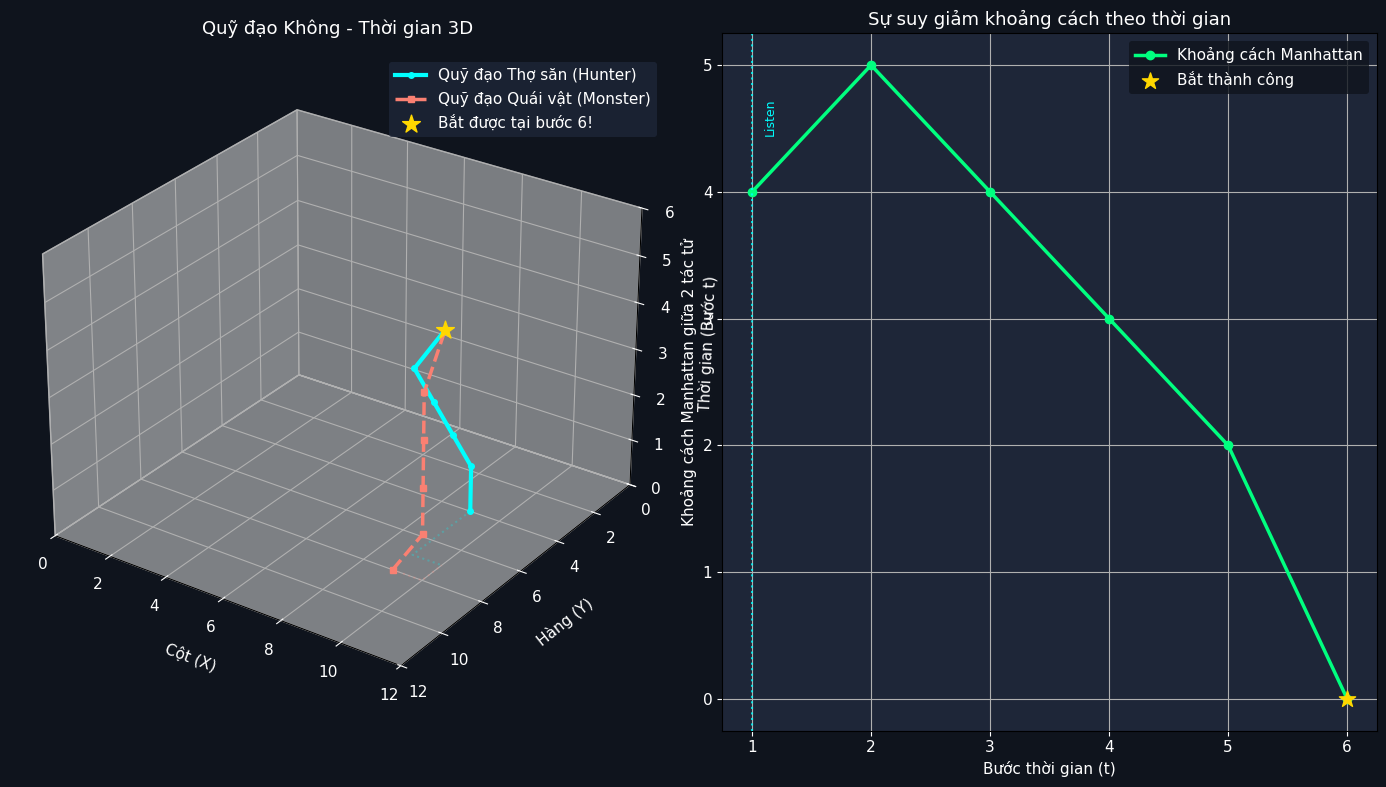

In [5]:
def plot_spacetime_trajectory_3d(history, title="Quỹ Đạo Không - Thời Gian 3D của Thợ Săn & Quái Vật"):
    """
    Vẽ quỹ đạo 3D Spacetime với trục Z là thời gian.
    """
    n = history['n']
    T = len(history['steps'])
    steps = np.array(history['steps'])
    
    h_x = history['hunter_coords'][:, 1]
    h_y = history['hunter_coords'][:, 0]
    m_x = history['monster_coords'][:, 1]
    m_y = history['monster_coords'][:, 0]
    
    fig = plt.figure(figsize=(14, 8))
    
    # 1. Đồ thị 3D Không - Thời gian
    ax3d = fig.add_subplot(121, projection='3d')
    ax3d.set_facecolor('#0f141d')
    fig.patch.set_facecolor('#0f141d')
    
    # Vẽ quỹ đạo 3D
    ax3d.plot(h_x, h_y, steps, color='cyan', lw=3, label='Quỹ đạo Thợ săn (Hunter)', marker='o', markersize=4)
    ax3d.plot(m_x, m_y, steps, color='salmon', lw=2.5, linestyle='--', label='Quỹ đạo Quái vật (Monster)', marker='s', markersize=4)
    
    # Vẽ hình chiếu bóng (Shadow projection) xuống đáy sàn z=0
    ax3d.plot(h_x, h_y, np.zeros(T), color='cyan', alpha=0.25, lw=1.5, linestyle=':')
    ax3d.plot(m_x, m_y, np.zeros(T), color='salmon', alpha=0.25, lw=1.5, linestyle=':')
    
    # Đánh dấu điểm bắt được
    if history['caught_step'] is not None:
        c_step = history['caught_step']
        ax3d.scatter([h_x[c_step]], [h_y[c_step]], [c_step], color='gold', s=180, marker='*', label=f'Bắt được tại bước {c_step+1}!')
        
    ax3d.set_xlim(0, n)
    ax3d.set_ylim(n, 0) # Đảo ngược trục hàng để North ở trên
    ax3d.set_zlim(0, max(T, 5))
    ax3d.set_xlabel('Cột (X)', color='white', labelpad=10)
    ax3d.set_ylabel('Hàng (Y)', color='white', labelpad=10)
    ax3d.set_zlabel('Thời gian (Bước t)', color='white', labelpad=10)
    ax3d.tick_params(colors='white')
    ax3d.set_title("Quỹ đạo Không - Thời gian 3D", color='white', fontsize=13, pad=15)
    ax3d.legend(loc='upper right', facecolor='#1e2638', edgecolor='none', labelcolor='white')
    ax3d.view_init(elev=28, azim=-55)
    
    # 2. Đồ thị suy giảm khoảng cách theo thời gian (Distance Decay Profile)
    ax2d = fig.add_subplot(122)
    ax2d.set_facecolor('#1e2638')
    ax2d.plot(steps + 1, history['distances'], color='springgreen', lw=2.5, marker='o', label='Khoảng cách Manhattan')
    
    # Đánh dấu các bước Thợ săn lắng nghe ('listen')
    for l_step in history['listened_steps']:
        ax2d.axvline(x=l_step + 1, color='cyan', linestyle=':', alpha=0.8)
        ax2d.text(l_step + 1.1, ax2d.get_ylim()[1]*0.85, 'Listen', color='cyan', fontsize=9, rotation=90)
        
    if history['caught_step'] is not None:
        ax2d.scatter([history['caught_step'] + 1], [0], color='gold', s=150, marker='*', zorder=5, label='Bắt thành công')
        
    ax2d.set_xlabel('Bước thời gian (t)', color='white')
    ax2d.set_ylabel('Khoảng cách Manhattan giữa 2 tác tử', color='white')
    ax2d.tick_params(colors='white')
    ax2d.set_title("Sự suy giảm khoảng cách theo thời gian", color='white', fontsize=13)
    ax2d.legend(facecolor='#0f141d', edgecolor='none', labelcolor='white')
    
    plt.tight_layout()
    plt.show()

# Vẽ đồ thị Spacetime cho ván đấu mô phỏng
plot_spacetime_trajectory_3d(demo_history)


## 3. Thử Nghiệm Đối Đầu Đa Kịch Bản Trong Không Gian 3D

Chúng ta hãy đặt Tác tử Thợ săn vào 2 kịch bản đối đầu hoàn toàn khác nhau để quan sát sự khác biệt về quỹ đạo 3D:
1. **Kịch bản 1 (Thợ săn vs Quái vật ngẫu nhiên - Simple Monster)**: Quái vật ít di chuyển, Thợ săn nhanh chóng khép góc và bắt thành công.
2. **Kịch bản 2 (Thợ săn vs Quái vật né tránh thông minh - Evasive Monster)**: Quái vật luôn tính toán khoảng cách Euclid và chủ động tháo chạy khi Thợ săn đến gần, tạo nên cuộc rượt đuổi kịch tính trên không gian 3D.


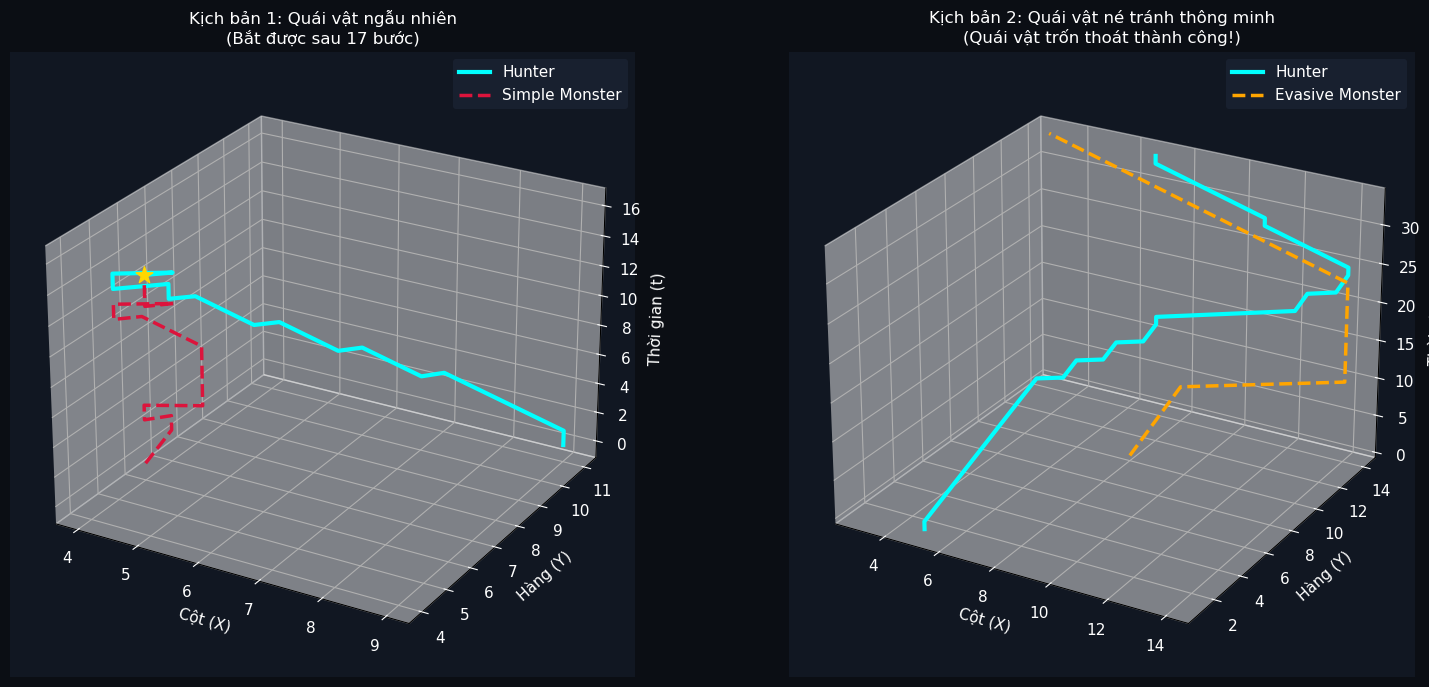

BÁO CÁO ĐỐI ĐẦU ĐA KỊCH BẢN:
1. Đối đầu Quái vật ngẫu nhiên: Kết thúc sau 17 bước (Bắt được: True)
2. Đối đầu Quái vật né tránh:  Kết thúc sau 35 bước (Bắt được: False)


In [6]:
# Chạy Kịch bản 1: Thợ săn vs Quái vật ngẫu nhiên
model_based_hunter_agent.target_monster_pos = None
model_based_hunter_agent.last_hunter_pos = None
model_based_hunter_agent.last_action = None
hist_simple = arena_environment_3d(model_based_hunter_agent, monster_agent_function_simple, n=15, max_steps=35)

# Chạy Kịch bản 2: Thợ săn vs Quái vật né tránh thông minh
model_based_hunter_agent.target_monster_pos = None
model_based_hunter_agent.last_hunter_pos = None
model_based_hunter_agent.last_action = None
hist_evasive = arena_environment_3d(model_based_hunter_agent, 
                                    lambda h, m: monster_agent_function_evasive(h, m, n=15), 
                                    n=15, max_steps=35)

# Vẽ biểu đồ so sánh 3D hai kịch bản cạnh nhau
fig_comp = plt.figure(figsize=(16, 7))
fig_comp.patch.set_facecolor('#0b0e14')

# Subplot 1: Kịch bản 1
ax1 = fig_comp.add_subplot(121, projection='3d')
ax1.set_facecolor('#111722')
ax1.plot(hist_simple['hunter_coords'][:, 1], hist_simple['hunter_coords'][:, 0], hist_simple['steps'], color='cyan', lw=3, label='Hunter')
ax1.plot(hist_simple['monster_coords'][:, 1], hist_simple['monster_coords'][:, 0], hist_simple['steps'], color='crimson', lw=2.5, linestyle='--', label='Simple Monster')
if hist_simple['caught_step'] is not None:
    c = hist_simple['caught_step']
    ax1.scatter([hist_simple['hunter_coords'][c, 1]], [hist_simple['hunter_coords'][c, 0]], [c], color='gold', s=160, marker='*')
ax1.set_title(f"Kịch bản 1: Quái vật ngẫu nhiên\n(Bắt được sau {len(hist_simple['steps'])} bước)", color='white', fontsize=12)
ax1.set_xlabel('Cột (X)', color='white')
ax1.set_ylabel('Hàng (Y)', color='white')
ax1.set_zlabel('Thời gian (t)', color='white')
ax1.tick_params(colors='white')
ax1.legend(facecolor='#1b2333', edgecolor='none', labelcolor='white')
ax1.view_init(elev=25, azim=-60)

# Subplot 2: Kịch bản 2
ax2 = fig_comp.add_subplot(122, projection='3d')
ax2.set_facecolor('#111722')
ax2.plot(hist_evasive['hunter_coords'][:, 1], hist_evasive['hunter_coords'][:, 0], hist_evasive['steps'], color='cyan', lw=3, label='Hunter')
ax2.plot(hist_evasive['monster_coords'][:, 1], hist_evasive['monster_coords'][:, 0], hist_evasive['steps'], color='orange', lw=2.5, linestyle='--', label='Evasive Monster')
if hist_evasive['caught_step'] is not None:
    c = hist_evasive['caught_step']
    ax2.scatter([hist_evasive['hunter_coords'][c, 1]], [hist_evasive['hunter_coords'][c, 0]], [c], color='gold', s=160, marker='*')
status_str = f"Bắt được sau {len(hist_evasive['steps'])} bước" if hist_evasive['caught_step'] is not None else "Quái vật trốn thoát thành công!"
ax2.set_title(f"Kịch bản 2: Quái vật né tránh thông minh\n({status_str})", color='white', fontsize=12)
ax2.set_xlabel('Cột (X)', color='white')
ax2.set_ylabel('Hàng (Y)', color='white')
ax2.set_zlabel('Thời gian (t)', color='white')
ax2.tick_params(colors='white')
ax2.legend(facecolor='#1b2333', edgecolor='none', labelcolor='white')
ax2.view_init(elev=25, azim=-60)

plt.tight_layout()
plt.show()

# Hiển thị tóm tắt bằng văn bản
print("=" * 80)
print("BÁO CÁO ĐỐI ĐẦU ĐA KỊCH BẢN:")
print(f"1. Đối đầu Quái vật ngẫu nhiên: Kết thúc sau {len(hist_simple['steps'])} bước (Bắt được: {hist_simple['caught_step'] is not None})")
print(f"2. Đối đầu Quái vật né tránh:  Kết thúc sau {len(hist_evasive['steps'])} bước (Bắt được: {hist_evasive['caught_step'] is not None})")
print("=" * 80)


## 4. Tổng Kết & Ý Nghĩa Học Thuật

### Trực quan hóa 3D mang lại những hiểu biết gì?
1. **Tính chất hội tụ trong không - thời gian**:
   - Khi quan sát trên mặt phẳng 2D, ta chỉ thấy các điểm nhảy trên lưới. Tuy nhiên trên trục không - thời gian 3D, đường cong của Thợ săn có độ dốc ổn định thể hiện vận tốc tiếp cận đều đặn, khép dần khoảng cách với Quái vật.
2. **Vai trò của bộ nhớ nội bộ (Internal Model)**:
   - Tại các bước lắng nghe (`'listen'`), Thợ săn dừng lại (vận tốc tức thời bằng 0 trên mặt phẳng $XY$, chỉ tiến trên trục thời gian $Z$). Tuy nhiên, thông tin tọa độ thu được cho phép Thợ săn đổi hướng đột ngột và di chuyển thẳng tắp đến vị trí con mồi.
3. **Sự khác biệt khi đối đầu Quái vật né tránh**:
   - Khi Quái vật biết né tránh, quỹ đạo 3D không còn hội tụ nhanh chóng mà phân nhánh, tạo ra các đường xoắn ốc quanh biên bàn cờ, minh họa rõ nét bản chất của trò chơi truy đuổi - né tránh (Pursuit-Evasion Game) trong lý thuyết trò chơi và AI.
